# 02 — The bigram as an `nn.Module`: embedding, cross-entropy, SGD vs AdamW

**Chapter 2** · suggested time: 35 min · CPU only · [![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/zenocode-org/ai-masterclass/blob/main/en/chapter_2/02_bigram_nn_module.ipynb)

![Roadmap](https://raw.githubusercontent.com/zenocode-org/ai-masterclass/main/en/chapter_2/figures/00_roadmap.png)

In chapter 1, we wrote the bigram "by hand": a `(27, 27)` matrix `W`, a one-hot, a softmax, an NLL, and `W -= lr * W.grad`. We now rewrite **exactly the same model** with PyTorch's standard tools, the ones we will use for the GPT:

| Chapter 1 (by hand) | Chapter 2 (PyTorch) |
|---|---|
| `W = torch.randn(27, 27, requires_grad=True)` | `nn.Embedding(V, V)` inside an `nn.Module` |
| `one_hot(x) @ W` | `embedding(x)` |
| `softmax` + `-log(p).mean()` | `F.cross_entropy(logits, y)` |
| `W -= lr * W.grad` | `optimizer.step()` (SGD or **AdamW**) |

**By the end of this notebook you will be able to:**
1. write a model as a subclass of `nn.Module`;
2. explain why `nn.Embedding(V, V)` *is* the matrix `W` from chapter 1;
3. explain what `F.cross_entropy` computes and why we give it **logits**;
4. compare **SGD** and **AdamW** and explain why AdamW is the default choice;
5. train the bigram for 120 steps and generate 120 characters.

In [1]:
# On Google Colab: fetch the course repository (corpora + shared modules such as minigpt.py).
# Locally, this cell does nothing.
import os, sys
if "google.colab" in sys.modules and not os.path.exists("minigpt.py"):
    if not os.path.exists("ai-masterclass"):
        !git clone -q --depth 1 https://github.com/zenocode-org/ai-masterclass
    %cd ai-masterclass/en/chapter_2

In [2]:
# Setup: imports and the chapter's shared module
import math
import torch
import torch.nn as nn
from torch.nn import functional as F
import matplotlib.pyplot as plt

import minigpt  # the file minigpt.py, next to this notebook
torch.manual_seed(1337)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch", torch.__version__, "| device:", device)

CORPUS = "shakespeare"
text, tok, train_data, val_data = minigpt.prepare_data(CORPUS)
V = tok.vocab_size
print(f"{CORPUS}: V = {V}, train = {len(train_data):,} characters")

PyTorch 2.15.0+cu132 | device: cuda
shakespeare: V = 65, train = 1,003,854 characters


## 1. `nn.Module`: the "box" that holds the parameters

A PyTorch model is a class that inherits from `nn.Module`. Two methods are enough:

- `__init__`: we **declare the layers** (and therefore their parameters);
- `forward`: we describe the **computation** from inputs to outputs.

In exchange, `nn.Module` gives us for free:
- `model(x)` calls `model.forward(x)`;
- `model.parameters()` lists **all** the trainable parameters, even those of sub-layers: this is what we will give to the optimizer;
- `model.train()` / `model.eval()` (useful for dropout, notebook 06), `model.to(device)`, saving, etc.

In [3]:
class MiniExample(nn.Module):
    def __init__(self):
        super().__init__()
        self.W = nn.Parameter(torch.randn(3, 3))   # a parameter "by hand"
        self.layer = nn.Linear(3, 2)               # a layer that holds its own parameters

    def forward(self, x):
        return self.layer(x @ self.W)


m = MiniExample()
for name, p in m.named_parameters():
    print(f"{name:15s} {tuple(p.shape)}  requires_grad={p.requires_grad}")
print("output:", m(torch.ones(1, 3)).shape)

W               (3, 3)  requires_grad=True
layer.weight    (2, 3)  requires_grad=True
layer.bias      (2,)  requires_grad=True
output: torch.Size([1, 2])


## 2. `nn.Embedding(V, V)`: the matrix `W` from chapter 1

![The bigram as an nn.Module](https://raw.githubusercontent.com/zenocode-org/ai-masterclass/main/en/chapter_2/figures/02_bigram.png)

`nn.Embedding(V, D)` is a table with `V` rows and `D` columns, initialized at random (normal distribution `N(0, 1)`). Giving it an index `i` means **reading row `i`**.

In chapter 1 we showed that `one_hot(i) @ W` selects row `i` of `W`. `nn.Embedding` does **the same thing without building the one-hot**: it is faster and uses less memory. Let's check it.

In [4]:
emb = nn.Embedding(V, V)
idx = torch.tensor([tok.stoi["e"], tok.stoi["h"], tok.stoi["e"]])

via_embedding = emb(idx)                                   # (3, V)
via_one_hot = F.one_hot(idx, num_classes=V).float() @ emb.weight   # (3, V)
via_indexing = emb.weight[idx]                             # (3, V)

print("shape:", tuple(via_embedding.shape))
print("embedding == one_hot @ W ?", torch.allclose(via_embedding, via_one_hot))
print("embedding == W[idx] ?     ", torch.allclose(via_embedding, via_indexing))
print("Two 'e' -> the same row twice?", torch.equal(via_embedding[0], via_embedding[2]))

shape: (3, 65)
embedding == one_hot @ W ? True
embedding == W[idx] ?      True
Two 'e' -> the same row twice? True


In the bigram, the table has **V columns**: the row we read directly contains **one score per possible next character**. These scores are called **logits**: arbitrary real numbers that only become probabilities after a softmax.

> In the GPT, we will use `nn.Embedding(V, C)` with `C` ≠ `V`: the row we read will no longer be a prediction, but a **feature vector** of size `C` that the following layers will transform.

### The bigram model

In this notebook, the input is a simple vector of `N` characters (one position per example). Notebook 03 will extend it to `(B, T)` sequences.

In [5]:
class BigramLanguageModel(nn.Module):

    def __init__(self, vocab_size):
        super().__init__()
        # Row i = the logits `W` of the character that follows character i.
        self.token_embedding_table = nn.Embedding(vocab_size, vocab_size)

    def forward(self, idx, targets=None):
        logits = self.token_embedding_table(idx)        # (N,) -> (N, V)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits, targets)     # targets: (N,)
        return logits, loss

    @torch.no_grad()
    def generate(self, start, max_new_tokens):
        out = [start]
        for _ in range(max_new_tokens):
            logits, _ = self(torch.tensor([out[-1]]))   # (1, V): only the LAST character matters
            probs = F.softmax(logits, dim=-1)
            out.append(torch.multinomial(probs[0], num_samples=1).item())
        return out


torch.manual_seed(1337)
model = BigramLanguageModel(V)
print(model)
print("parameters:", sum(p.numel() for p in model.parameters()), "=", V, "×", V)

BigramLanguageModel(
  (token_embedding_table): Embedding(65, 65)
)
parameters: 4225 = 65 × 65


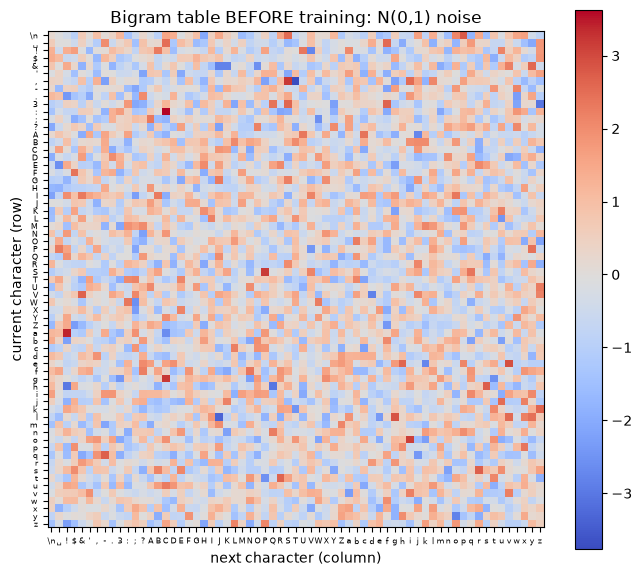

In [6]:
def heatmap(matrix, title):
    fig, ax = plt.subplots(figsize=(8, 7))
    im = ax.imshow(matrix.detach(), cmap="coolwarm")
    labels = [{"\n": "\\n", " ": "␣"}.get(c, c) for c in tok.chars]
    ax.set_xticks(range(V), labels, fontsize=6); ax.set_yticks(range(V), labels, fontsize=6)
    ax.set_xlabel("next character (column)"); ax.set_ylabel("current character (row)")
    ax.set_title(title); fig.colorbar(im, ax=ax); plt.show()

heatmap(model.token_embedding_table.weight, "Bigram table BEFORE training: N(0,1) noise")

## 3. `F.cross_entropy`: softmax + NLL in a single function

In chapter 1, the loss was computed in four steps:

$$\text{logits} \xrightarrow{\exp} \text{positive weights} \xrightarrow{\div\,\Sigma} \text{probabilities} \xrightarrow{-\log p_{\text{correct answer}}\,,\ \text{mean}} \mathcal{L}$$

`F.cross_entropy(logits, targets)` does **exactly** that, in one line:

$$\mathcal{L} = -\frac{1}{N}\sum_{n=1}^{N} \log \frac{e^{\,\text{logits}[n,\,y_n]}}{\sum_{j} e^{\,\text{logits}[n,\,j]}}$$

Three things to remember:
1. We give it **logits**, not probabilities (the softmax is done inside).
2. The targets are class **indices** (`torch.long`), not one-hots.
3. Expected shapes: logits `(N, V)` and targets `(N,)`. This constraint is the reason for the *reshape* in notebook 03.

In [7]:
torch.manual_seed(0)
ix = torch.randint(len(train_data) - 1, (8,))
x, y = train_data[ix], train_data[ix + 1]           # 8 (character, next) pairs
logits, loss = model(x, y)

# The same thing "by hand", as in chapter 1:
probs = logits.exp() / logits.exp().sum(dim=1, keepdim=True)
p_correct = probs[torch.arange(len(y)), y]
loss_by_hand = -p_correct.log().mean()

for c1, c2, p in zip(x, y, p_correct):
    print(f"{tok.itos[c1.item()]!r:6} -> {tok.itos[c2.item()]!r:6}  p(correct answer) = {p.item():.4f}")
print(f"\nF.cross_entropy: {loss.item():.4f}")
print(f"by hand        : {loss_by_hand.item():.4f}")

'e'    -> ' '     p(correct answer) = 0.0063
's'    -> 'i'     p(correct answer) = 0.0199
'h'    -> 'e'     p(correct answer) = 0.0074
'e'    -> 't'     p(correct answer) = 0.0285
','    -> ' '     p(correct answer) = 0.0114
'.'    -> '\n'    p(correct answer) = 0.0328
':'    -> '\n'    p(correct answer) = 0.0021
'\n'   -> 'M'     p(correct answer) = 0.0016

F.cross_entropy: 4.7440
by hand        : 4.7440


### Why not do everything by hand? Numerical stability

`exp(1000)` exceeds the range of a `float32`: the "by hand" computation produces `inf`, then `nan`. `F.cross_entropy` uses the identity $\log\sum_j e^{z_j} = m + \log\sum_j e^{z_j - m}$ (with $m = \max_j z_j$) and never overflows.

In [8]:
extreme_logits = torch.tensor([[1000.0, 0.0, -1000.0]])
target = torch.tensor([0])
p = extreme_logits.exp() / extreme_logits.exp().sum()
print("by hand        :", (-p[0, 0].log()).item())
print("F.cross_entropy:", F.cross_entropy(extreme_logits, target).item())

by hand        : nan
F.cross_entropy: 0.0


### What loss should we expect at the start?

With zero logits, all probabilities would be `1/V` and the loss `log V`. Our table is initialized with `N(0, 1)`: the logits are noisy, the model is **wrongly confident** about some characters, and the initial loss is a bit **higher** than `log V`.

In [9]:
@torch.no_grad()
def val_loss(model):
    """Loss over ALL the (character, next) pairs of the validation set."""
    return model(val_data[:-1], val_data[1:])[1].item()

print(f"log(V)                  = {math.log(V):.3f}")
print(f"initial model loss      = {val_loss(model):.3f}")

log(V)                  = 4.174
initial model loss      = 4.724


## 4. Training: 120 steps (iterations)

The loop is the one from chapter 1, with two differences:
- at each step, we draw **256 random pairs** from the text instead of using the whole corpus (a *mini-batch*, detailed in notebook 03);
- the update is done by an **optimizer**: `zero_grad()` → `backward()` → `step()`.

In [10]:
def random_pairs(data, n=256):
    ix = torch.randint(len(data) - 1, (n,))
    return data[ix], data[ix + 1]


def train(model, optimizer, steps=120):
    history = []
    for _ in range(steps):
        x, y = random_pairs(train_data)
        _, loss = model(x, y)                 # 1. forward + loss
        optimizer.zero_grad(set_to_none=True) # 2. clear the old gradients
        loss.backward()                       # 3. compute the new ones
        optimizer.step()                      # 4. update the weights
        history.append(loss.item())
    return history


torch.manual_seed(1337)
model = BigramLanguageModel(V)
opt = torch.optim.AdamW(model.parameters(), lr=1e-3)
h = train(model, opt, steps=120)
print(f"loss: {h[0]:.3f} -> {h[-1]:.3f}   (validation: {val_loss(model):.3f})")
print(tok.decode(model.generate(tok.stoi["\n"], 120)))

loss: 4.745 -> 4.721   (validation: 4.584)

u!d?s&oCJ;SJAXxa;TvGSSaXiGr'T;.,.s:BMgX:C'P IBb?HdnDM&SP!Utgi,lyJhsgZdZ?yNX$C&DH:EOtRjK$ dlywOE;dbGvbwpC-o.SB!BX &ZyYV&k


**Almost nothing has moved.** With `lr = 1e-3`, each step changes the weights by about a thousandth: 120 steps are not enough for a table of 4,225 numbers. The generated text is still noise.

Before "turning up the learning rate at random", let's understand what the optimizer does.

---
## 5. SGD vs AdamW: how gradients become updates

`loss.backward()` computes, for each weight $w$, its derivative $g = \partial \mathcal{L} / \partial w$. **The optimizer decides what to do with it.**

### SGD (*stochastic gradient descent*)

This is the rule from chapter 1:

$$w \leftarrow w - \eta\, g$$

- "stochastic" because $g$ is computed on a randomly drawn **mini-batch**: it is a noisy estimate of the true gradient;
- **a single** learning rate $\eta$ for all the weights;
- the step size is **proportional to the gradient**: a weight whose gradient is tiny barely moves.

### Adam / AdamW

Adam keeps, **for each weight**, two moving averages:

$$m \leftarrow \beta_1 m + (1-\beta_1)\,g \qquad\text{(average direction: "momentum")}$$
$$v \leftarrow \beta_2 v + (1-\beta_2)\,g^2 \qquad\text{(typical gradient magnitude)}$$

then updates with

$$w \leftarrow w - \eta\,\frac{\hat m}{\sqrt{\hat v} + \varepsilon}$$

($\hat m$, $\hat v$: versions corrected for the start-up bias, since $m$ and $v$ start at 0.)

**What you need to understand:** the ratio $\hat m / \sqrt{\hat v}$ is of the order of **±1**, whatever the scale of the gradient. So each weight moves by about $\eta$ per step: **the step size no longer depends on the size of the gradient**, only on its consistency.

### The "W" in AdamW: decoupled *weight decay*

AdamW adds a slight pull of the weights toward 0: $w \leftarrow w - \eta\,\lambda\,w$, applied **separately** from the adaptive update (Loshchilov & Hutter, 2019). This prevents weights from becoming needlessly large. In PyTorch, `AdamW` uses $\lambda = 0.01$ by default.

Let's check on a single weight that the formula above is indeed what PyTorch does.

In [11]:
# A single AdamW step computed by hand, compared with torch.optim.AdamW
w = torch.tensor([0.5], requires_grad=True)
opt = torch.optim.AdamW([w], lr=0.1, betas=(0.9, 0.999), eps=1e-8, weight_decay=0.01)
g = torch.tensor([3.0])                    # suppose this is the gradient
w.grad = g.clone()
w_before = w.item()
opt.step()

m = (1 - 0.9) * g;  v = (1 - 0.999) * g**2          # m and v start at 0
m_hat = m / (1 - 0.9);  v_hat = v / (1 - 0.999)    # bias correction (step 1)
w_by_hand = w_before * (1 - 0.1 * 0.01)            # decoupled weight decay
w_by_hand = w_by_hand - 0.1 * m_hat / (v_hat.sqrt() + 1e-8)
print(f"PyTorch: {w.item():.6f} | by hand: {w_by_hand.item():.6f}")
print("The gradient was 3, but the step is ≈ lr = 0.1: Adam normalizes the magnitude.")

PyTorch: 0.399500 | by hand: 0.399500
The gradient was 3, but the step is ≈ lr = 0.1: Adam normalizes the magnitude.


### Why this matters for our bigram

Let's look at the **scale of the gradients** of the table. With 256 pairs per batch, a row of the table only receives a gradient if its character appears in the batch, and the loss is a **mean** over 256 examples: the gradients are tiny.

In [12]:
torch.manual_seed(1337)
model = BigramLanguageModel(V)
x, y = random_pairs(train_data)
_, loss = model(x, y)
loss.backward()
g = model.token_embedding_table.weight.grad
print(f"mean |gradient|        : {g.abs().mean():.2e}")
print(f"max |gradient|         : {g.abs().max():.2e}")
print(f"rows without gradient  : {(g.abs().sum(1) == 0).sum().item()} / {V}")
print("With SGD and lr=1e-3, a weight moves by ~1e-3 × 1e-4 = 1e-7 per step!")

mean |gradient|        : 4.33e-04
max |gradient|         : 3.05e-02
rows without gradient  : 27 / 65
With SGD and lr=1e-3, a weight moves by ~1e-3 × 1e-4 = 1e-7 per step!


### Experiment: same model, same initialization, same data — only the optimizer changes

**Predict before running:** which optimizer will reach the lowest loss in 120 steps? Do both need the same learning rate?

SGD   lr=1e-3: train loss 4.868 | val 4.723


SGD   lr=1: train loss 4.030 | val 4.049


SGD   lr=10: train loss 2.731 | val 2.893


AdamW lr=1e-3: train loss 4.721 | val 4.584


AdamW lr=1e-2: train loss 3.634 | val 3.574


AdamW lr=1e-1: train loss 2.348 | val 2.541


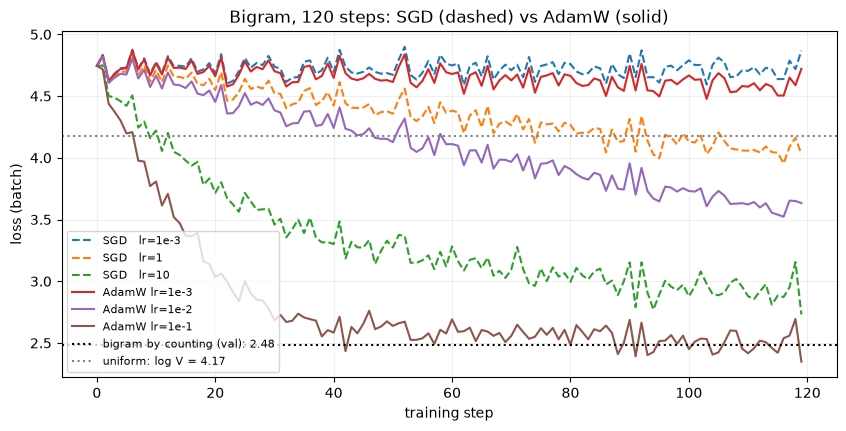

In [13]:
configs = {
    "SGD   lr=1e-3": lambda p: torch.optim.SGD(p, lr=1e-3),
    "SGD   lr=1":    lambda p: torch.optim.SGD(p, lr=1.0),
    "SGD   lr=10":   lambda p: torch.optim.SGD(p, lr=10.0),
    "AdamW lr=1e-3": lambda p: torch.optim.AdamW(p, lr=1e-3),
    "AdamW lr=1e-2": lambda p: torch.optim.AdamW(p, lr=1e-2),
    "AdamW lr=1e-1": lambda p: torch.optim.AdamW(p, lr=1e-1),
}
results, models = {}, {}
for name, factory in configs.items():
    torch.manual_seed(1337)                      # same initialization AND same batches
    m = BigramLanguageModel(V)
    results[name] = train(m, factory(m.parameters()), steps=120)
    models[name] = m
    print(f"{name}: train loss {results[name][-1]:.3f} | val {val_loss(m):.3f}")

# Reference: the best possible bigram, obtained by COUNTING (chapter 1, with +1 smoothing)
N = torch.ones(V, V)
N.index_put_((train_data[:-1], train_data[1:]), torch.ones(len(train_data) - 1), accumulate=True)
P = N / N.sum(1, keepdim=True)
counts_loss = -P[val_data[:-1], val_data[1:]].log().mean().item()

fig, ax = plt.subplots(figsize=(10, 4.5))
for name, h in results.items():
    ax.plot(h, label=name, linestyle="-" if "Adam" in name else "--")
ax.axhline(counts_loss, color="black", linestyle=":", label=f"bigram by counting (val): {counts_loss:.2f}")
ax.axhline(math.log(V), color="gray", linestyle=":", label=f"uniform: log V = {math.log(V):.2f}")
ax.set_xlabel("training step"); ax.set_ylabel("loss (batch)"); ax.legend(fontsize=8); ax.grid(alpha=.2)
ax.set_title("Bigram, 120 steps: SGD (dashed) vs AdamW (solid)")
plt.show()

**Reading the curves:**

- At `lr = 1e-3`, **neither** of them learns in 120 steps.
- SGD needs a **huge** learning rate (`10`) to make up for the tiny gradients. This setting would make no sense for another model.
- AdamW almost reaches the bigram optimum (the "counting" line) with `lr = 0.1`, because its step size does not depend on the scale of the gradient.

**Why AdamW for the GPT?** The GPT contains parameters of very different kinds (embeddings, Q/K/V projections, FeedForward, LayerNorm) whose gradients have very different scales. With SGD, you would have to tune a learning rate per layer; AdamW adapts **weight by weight**. It is the default optimizer for Transformers (GPT-2, GPT-3, LLaMA…).

> **Caveat:** `lr = 0.1` suits this small bigram. For the GPT, we will use `lr = 1e-3`: the right learning rate always depends on the model.

## 6. Generating 120 characters with the best bigram



Kitloulfe
Tht,
NThandirer:
TInd, onout, bend fe t y e tar ENTo lamstoX!qurd ct be thally plgnd he?

T:
TEDouthu
Le, ie 


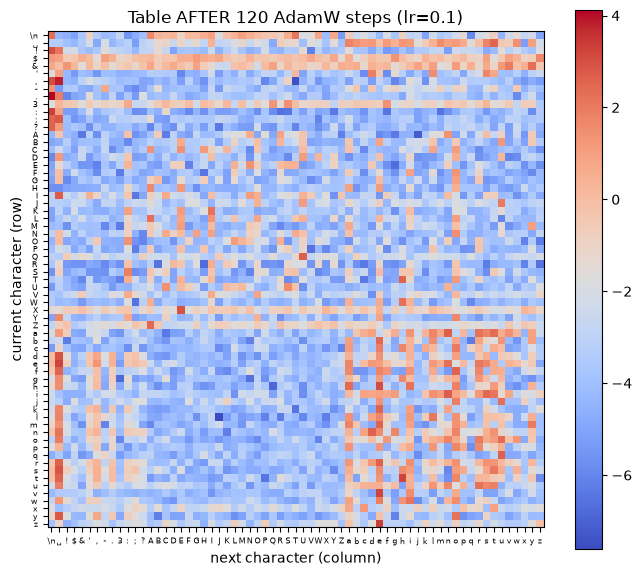

In [14]:
torch.manual_seed(42)
best = models["AdamW lr=1e-1"]
print(tok.decode(best.generate(tok.stoi["\n"], 120)))
heatmap(best.token_embedding_table.weight, "Table AFTER 120 AdamW steps (lr=0.1)")

**What we observe:** "words" of the right length, plausible spaces and line breaks, capital letters after `\n`… but no real words. In the table, structures start to appear (for example, the `␣` column is strong for many rows).

**The fundamental limit:** the bigram sees **only the last character**. After `"th"`, it does not know there was a `t`: it only sees `h`. To go further, each position must be able to **look at the previous characters**. This is what attention will do (notebook 05).

## Summary

- A model = a subclass of `nn.Module`: layers in `__init__`, computation in `forward`.
- `nn.Embedding(V, V)` = the matrix `W` from chapter 1; `emb(i)` = `one_hot(i) @ W` = `W[i]`.
- `F.cross_entropy(logits, targets)` = softmax + `-log p(correct answer)` + mean, **numerically stable**. Shapes: `(N, V)` and `(N,)`.
- Loop: `forward` → `zero_grad` → `backward` → `step`.
- **SGD**: step ∝ gradient, a single `lr`. **AdamW**: step normalized per weight (momentum + magnitude), plus decoupled *weight decay*. It is the standard for Transformers.

**Check your understanding**
1. Why is the initial loss higher than `log V`?
2. What would happen if we gave probabilities (after softmax) to `F.cross_entropy`?
3. Why does SGD need a learning rate of 10 here, while AdamW is happy with 0.1?
4. Why would forgetting `optimizer.zero_grad()` break training?

**Next → 03:** we will give the model **sequences** `(B, T)` instead of isolated pairs. This will require a *reshape* before the cross-entropy.

### References
- Andrej Karpathy, [*Let's build GPT: from scratch, in code, spelled out*](https://www.youtube.com/watch?v=kCc8FmEb1nY) (2023) and its code [ng-video-lecture](https://github.com/karpathy/ng-video-lecture).
- Y. Bengio et al., [*A Neural Probabilistic Language Model*](https://www.jmlr.org/papers/volume3/bengio03a/bengio03a.pdf), JMLR 2003 — the origin of embeddings for language.
- D. Kingma & J. Ba, [*Adam: A Method for Stochastic Optimization*](https://arxiv.org/abs/1412.6980), ICLR 2015.
- I. Loshchilov & F. Hutter, [*Decoupled Weight Decay Regularization*](https://arxiv.org/abs/1711.05101), ICLR 2019 — AdamW.
- S. Ruder, [*An overview of gradient descent optimization algorithms*](https://arxiv.org/abs/1609.04747), 2016 — a very good overview of SGD / momentum / Adam.
- PyTorch documentation: [`nn.Embedding`](https://pytorch.org/docs/stable/generated/torch.nn.Embedding.html), [`F.cross_entropy`](https://pytorch.org/docs/stable/generated/torch.nn.functional.cross_entropy.html), [`AdamW`](https://pytorch.org/docs/stable/generated/torch.optim.AdamW.html).